In [48]:
# 1. Import principali
import os
import json
import numpy as np
import pandas as pd

from qdrant_client import QdrantClient
from qdrant_client.models import Filter, FieldCondition, MatchValue

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

import matplotlib.pyplot as plt
import seaborn as sns


In [49]:
# 2. Parametri connessione Qdrant
QDRANT_HOST = "localhost"
QDRANT_PORT = 6333
QDRANT_COLLECTION = "tracks_embeddings"

client = QdrantClient(host=QDRANT_HOST, port=QDRANT_PORT)
client.get_collections()


CollectionsResponse(collections=[CollectionDescription(name='tracks_embeddings')])

Caricamento vettori da Qdrant

In [50]:
# 3. Recupero dei punti dalla collection
LIMIT = 30  # metti 50/100/200 a seconda di quanti brani hai indicizzato

points = client.scroll(
    collection_name=QDRANT_COLLECTION,
    limit=LIMIT,
    with_payload=True,
    with_vectors=True,
)[0]  # scroll() ritorna (points, next_page_offset)

numeroTracce=len(points)
print(f"Sono state indicizzate {numeroTracce} tracce")


Sono state indicizzate 20 tracce


Costruzione del DataFrame con vettori + metadata

In [51]:
# 4. Costruzione DataFrame
records = []

for p in points:
    vec = np.array(p.vector, dtype=float)
    payload = p.payload or {}
    #print(f"payload: {payload}")
    filename = payload.get("filename", f"id_{p.id}")
    top_genres = payload.get("top_genres", {})
    # prendo il genere principale (quello con score maggiore)
    if isinstance(top_genres, dict) and top_genres:
        main_genre = max(top_genres.items(), key=lambda x: x[1])[0]
    else:
        main_genre = "Unknown"

    records.append({
        "id": p.id,
        "filename": filename,
        "main_genre": main_genre,
        "vector": vec,
    })

df = pd.DataFrame(records)
df.head()


,id,filename,main_genre,vector
0,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Hard Bop,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,10f65c06-ae4a-436d-9ce2-18cac86e5e03,Free Bird-Lynyrd Skynyrd.mp3,Rock---Hard Rock,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,1136b8e5-af80-49fa-9668-1088573439fc,Red Hot Chili Peppers - Californication.mp3,Rock---Alternative Rock,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
3,191db64b-2962-4cf8-86ae-35070a7795ba,Hans Zimmer - Time.mp3,Stage & Screen---Soundtrack,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,223e85a6-445c-47a2-ad0a-c287bdbc7e13,Pink Floyd - Comfortably Numb.mp3,Rock---Pop Rock,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


In [52]:
#creiamo anche una matrice numpy solo dei vettori
X = np.vstack(df["vector"].values)  # shape: (N, 400)
X.shape

(20, 400)

Analisi descrittiva (EDA base)

Norme, media, varianza delle attivazioni

In [53]:
# 5. Norme dei vettori (quanto sono "lunghi")
norms = np.linalg.norm(X, axis=1)
df["norm"] = norms

print(df["norm"].describe())


count    2.000000e+01
mean     1.000000e+00
std      3.162914e-08
min      9.999999e-01
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: norm, dtype: float64


Dimensioni Attive non-zero

count    20.0
mean     10.0
std       0.0
min      10.0
25%      10.0
50%      10.0
75%      10.0
max      10.0
Name: active_dims, dtype: float64


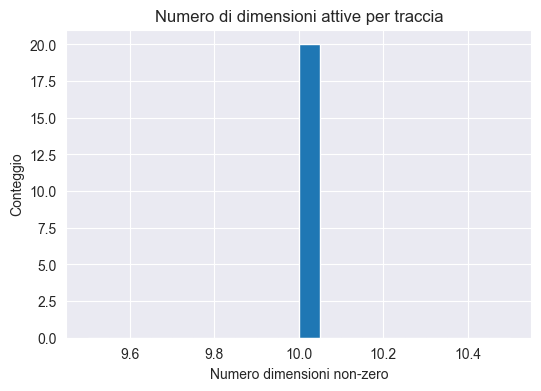

In [54]:
# 6. Numero di dimensioni attive (non zero) per vettore
active_dims = (X != 0).sum(axis=1)
df["active_dims"] = active_dims

print(df["active_dims"].describe())

plt.figure(figsize=(6,4))
df["active_dims"].hist(bins=20)
plt.title("Numero di dimensioni attive per traccia")
plt.xlabel("Numero dimensioni non-zero")
plt.ylabel("Conteggio")
plt.show()


Frequenza dei generi principali

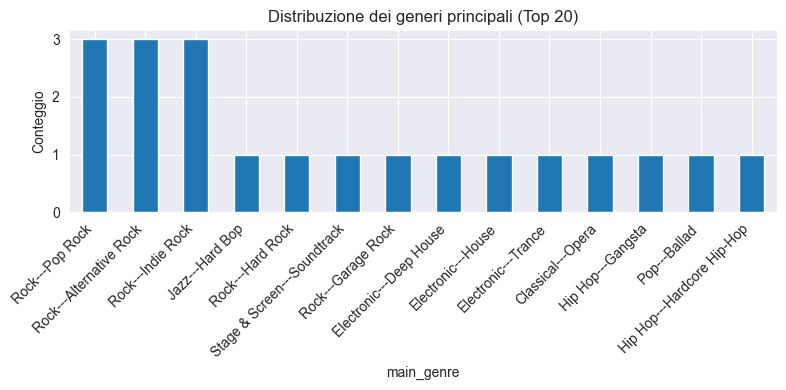

In [55]:
plt.figure(figsize=(8,4))
df["main_genre"].value_counts().head(20).plot(kind="bar")
plt.title("Distribuzione dei generi principali (Top 20)")
plt.ylabel("Conteggio")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


Matrice di similarità e heatmap

Similarità coseno tra le prime N tracce

In [56]:
N_SIM = min(40, len(df))
X_small = X[:N_SIM]
labels_small = df["filename"].head(N_SIM).tolist()

sim_matrix = cosine_similarity(X_small)
sim_matrix.shape


(20, 20)

Heatmap

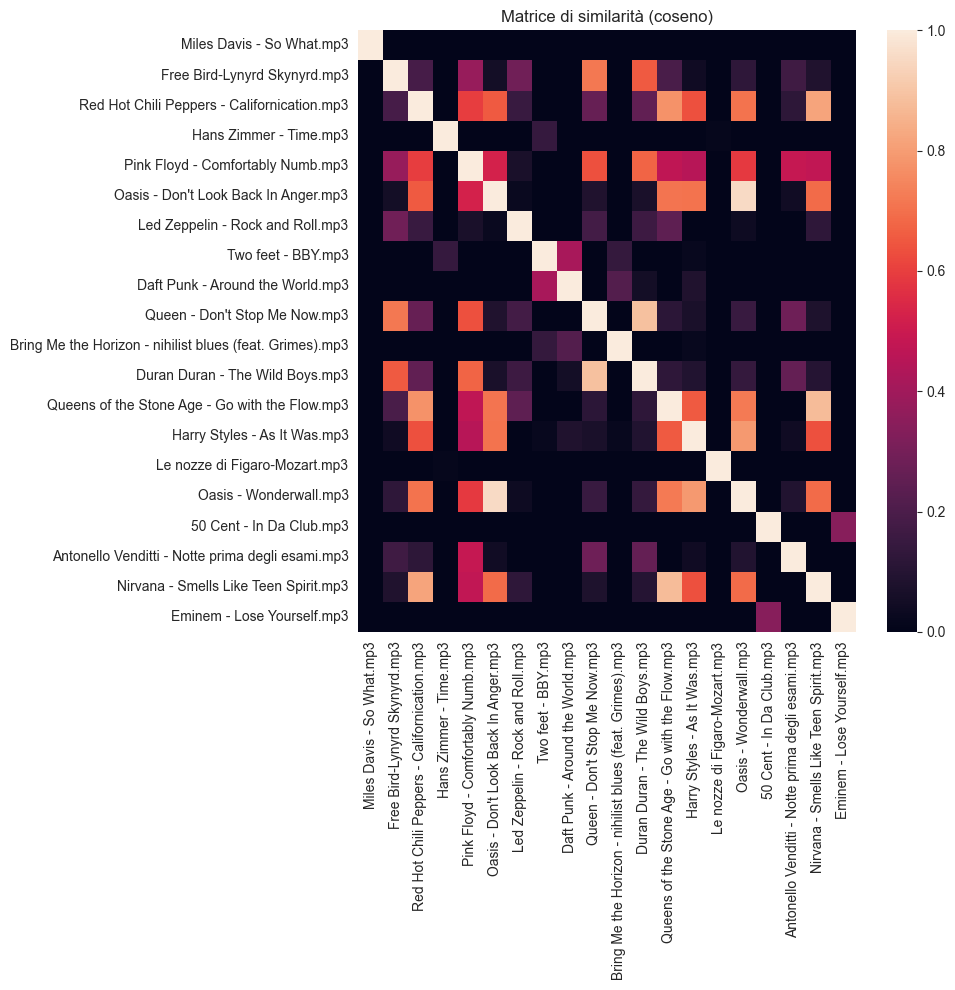

In [57]:
plt.figure(figsize=(10,10))
sns.heatmap(sim_matrix, xticklabels=labels_small, yticklabels=labels_small)
plt.title("Matrice di similarità (coseno)")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



Riduzione dimensionale (PCA + t-SNE)

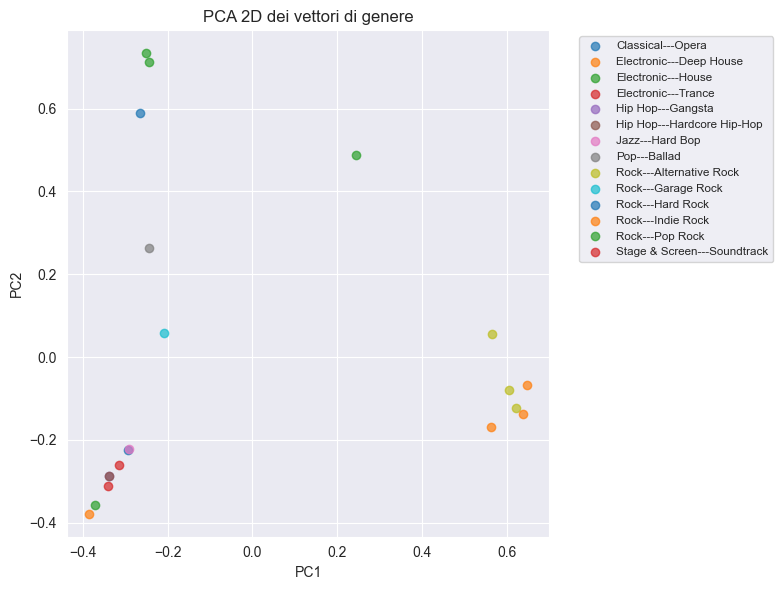

In [58]:
#PCA 2D
# PCA per riduzione grossolana
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

df["pca_x"] = X_pca[:,0]
df["pca_y"] = X_pca[:,1]

plt.figure(figsize=(8,6))
for g, sub in df.groupby("main_genre"):
    plt.scatter(sub["pca_x"], sub["pca_y"], alpha=0.7, label=g)

plt.title("PCA 2D dei vettori di genere")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize="small")
plt.tight_layout()
plt.show()


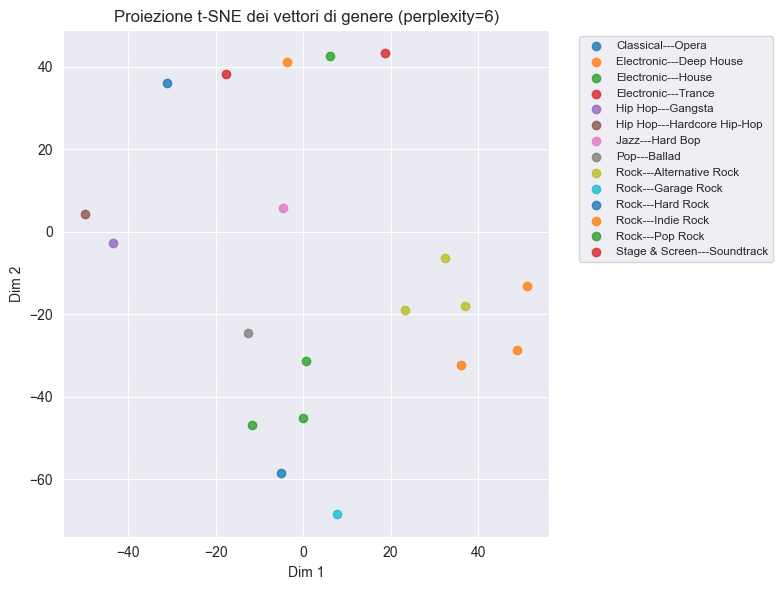

In [59]:
#t-SNE 2D
from sklearn.manifold import TSNE

n_samples = X.shape[0]

# se hai pochi punti, meglio una perplexity bassa
perplexity = min(10, max(5, n_samples // 3))  # es: con 20 sample → 6

tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    random_state=42,
    metric="cosine"
)
X_tsne = tsne.fit_transform(X)

df["tsne_x"] = X_tsne[:, 0]
df["tsne_y"] = X_tsne[:, 1]

plt.figure(figsize=(8, 6))
for g, sub in df.groupby("main_genre"):
    plt.scatter(sub["tsne_x"], sub["tsne_y"], alpha=0.8, label=g)
plt.title(f"Proiezione t-SNE dei vettori di genere (perplexity={perplexity})")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize="small")
plt.tight_layout()
plt.show()



Analisi delle Top-10 classi

In [60]:
# 7. Espansione dei top_genres in una lista lunga (genere, score)
rows = []
for _, row in df.iterrows():
    payload_point = next(p.payload for p in points if p.id == row["id"])
    #print(payload_point)
    top_genres = payload_point.get("top_genres", {})
    #print(top_genres)
    for genre, score in top_genres.items():
        rows.append({"id": row["id"], "filename": row["filename"],
                     "genre": genre, "score": score})

df_genres = pd.DataFrame(rows)
df_genres.head()
print(df_genres.head(50))


                                      id  \
0   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
1   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
2   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
3   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
4   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
5   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
6   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
7   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
8   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
9   0b8c10f4-cd4a-46f3-96dd-921b40a5df6a   
10  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
11  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
12  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
13  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
14  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
15  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
16  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
17  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
18  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
19  10f65c06-ae4a-436d-9ce2-18cac86e5e03   
20  1136b8e5-af80-49fa-9668-1088573439fc   
21  1136b8e5-af80-49fa-9668-1088

Istogramma dei generi più presenti nei Top-K

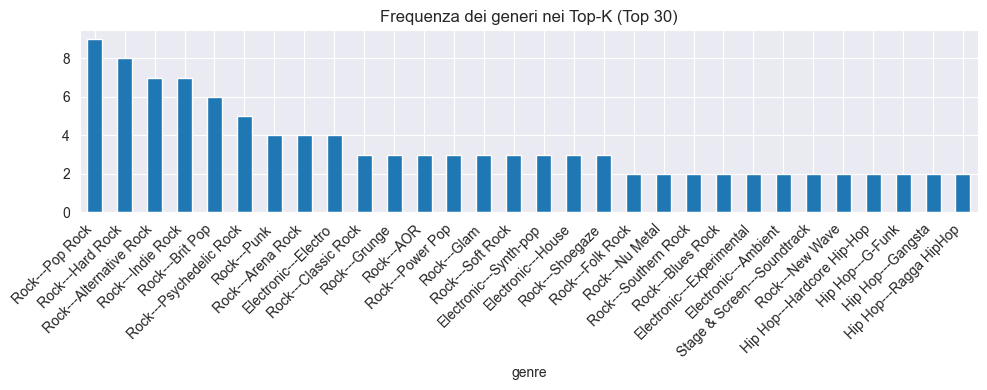

In [61]:
plt.figure(figsize=(10,4))
df_genres["genre"].value_counts().head(30).plot(kind="bar")
plt.title("Frequenza dei generi nei Top-K (Top 30)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


## Analisi univariata e multivariata dei generi

In [62]:
# Aggiungo la macro-categoria del genere (es. "Rock", "Jazz", "Electronic")
df_genres["macro_genre"] = df_genres["genre"].str.split("---").str[0]
df_genres.head(50)

,id,filename,genre,score,macro_genre
0,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Hard Bop,55.08,Jazz
1,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Bop,38.21,Jazz
2,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Post Bop,29.18,Jazz
3,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Cool Jazz,25.64,Jazz
4,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Modal,20.23,Jazz
5,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Contemporary Jazz,7.22,Jazz
6,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Soul-Jazz,6.65,Jazz
7,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Easy Listening,6.17,Jazz
8,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Big Band,4.99,Jazz
9,0b8c10f4-cd4a-46f3-96dd-921b40a5df6a,Miles Davis - So What.mp3,Jazz---Swing,4.68,Jazz


In [63]:
# Distribuzione assoluta delle macro-categorie
macro_counts = df_genres["macro_genre"].value_counts()

# Distribuzione percentuale
macro_perc = df_genres["macro_genre"].value_counts(normalize=True) * 100

display(macro_counts.to_frame("conteggio"))
display(macro_perc.round(2).to_frame("percentuale"))

,conteggio
macro_genre,
Rock,103
Electronic,38
Hip Hop,21
Classical,11
Jazz,10
Pop,6
Stage & Screen,4
"Folk, World, & Country",4
Funk / Soul,1


,percentuale
macro_genre,
Rock,51.5
Electronic,19.0
Hip Hop,10.5
Classical,5.5
Jazz,5.0
Pop,3.0
Stage & Screen,2.0
"Folk, World, & Country",2.0
Funk / Soul,0.5


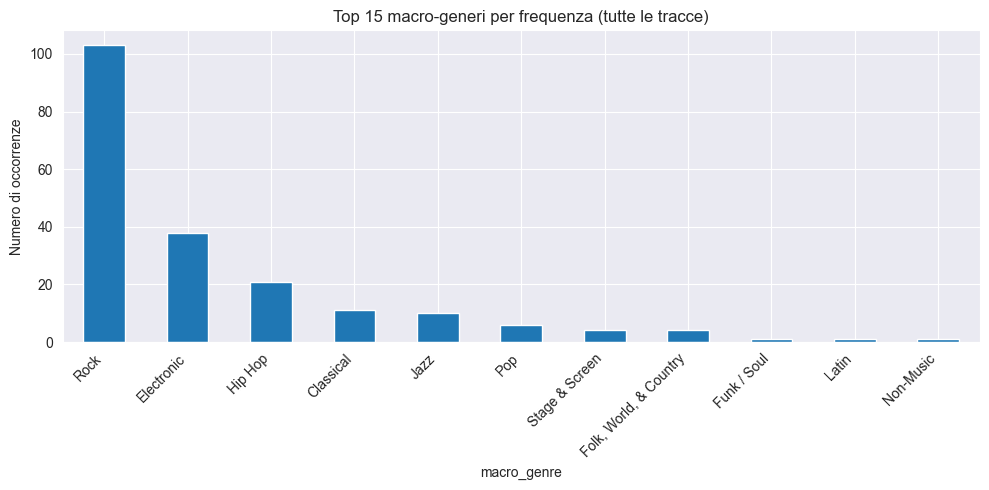

In [64]:

top_n = 15
macro_counts_top = macro_counts.head(top_n)

plt.figure(figsize=(10, 5))
macro_counts_top.plot(kind="bar")
plt.xticks(rotation=45, ha="right")
plt.title(f"Top {top_n} macro-generi per frequenza (tutte le tracce)")
plt.ylabel("Numero di occorrenze")
plt.tight_layout()
plt.show()


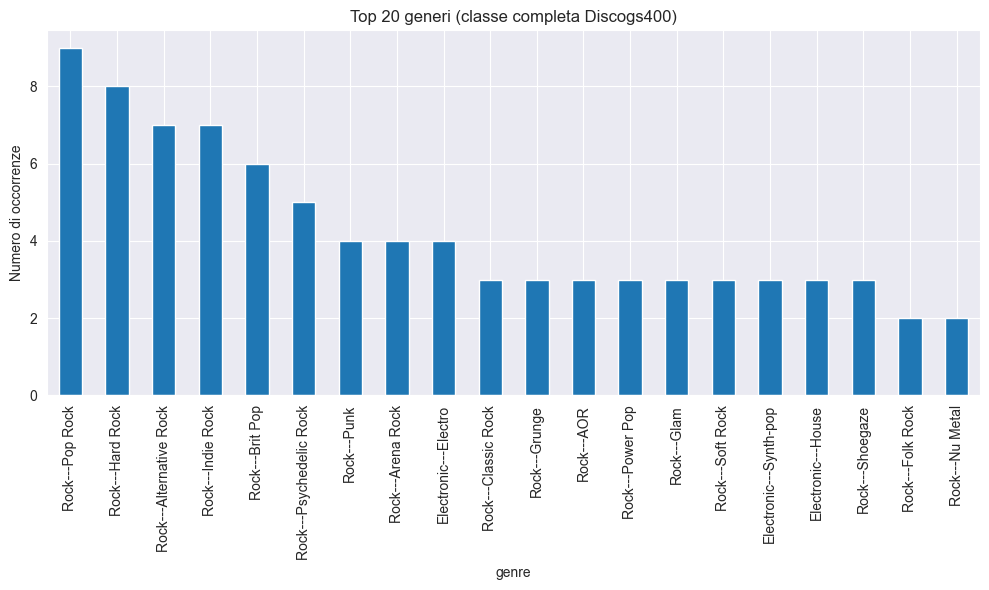

In [65]:
# Top 20 generi completi più frequenti
genre_counts = df_genres["genre"].value_counts()
top_n = 20
genre_counts_top = genre_counts.head(top_n)

plt.figure(figsize=(10, 6))
genre_counts_top.plot(kind="bar")
plt.xticks(rotation=90)
plt.title(f"Top {top_n} generi (classe completa Discogs400)")
plt.ylabel("Numero di occorrenze")
plt.tight_layout()
plt.show()


In [66]:
# Statistiche descrittive degli score raggruppati per macro-genere
stats_macro = df_genres.groupby("macro_genre")["score"].describe().sort_values("mean", ascending=False)
stats_macro.head(10)


,count,mean,std,min,25%,50%,75%,max
macro_genre,,,,,,,,
Jazz,10.0,19.805000,17.226554,4.68,6.2900,13.725,28.2950,55.08
Classical,11.0,16.657273,15.790002,3.91,7.2150,8.470,22.2200,52.64
Stage & Screen,4.0,15.970000,12.172981,1.90,7.7650,17.560,25.7650,26.86
Hip Hop,21.0,15.695238,15.078680,2.23,6.6400,10.970,17.8700,67.02
Rock,103.0,13.711165,10.780173,3.63,6.4350,10.530,15.7400,60.77
Electronic,38.0,10.618158,6.682037,4.82,6.3600,8.185,12.3675,37.40
Pop,6.0,8.733333,3.453952,3.57,7.4525,8.155,11.1975,13.09
"Folk, World, & Country",4.0,6.447500,2.660819,3.75,4.4475,6.350,8.3500,9.34
Funk / Soul,1.0,5.890000,NaN,5.89,5.8900,5.890,5.8900,5.89


<Figure size 1000x600 with 0 Axes>

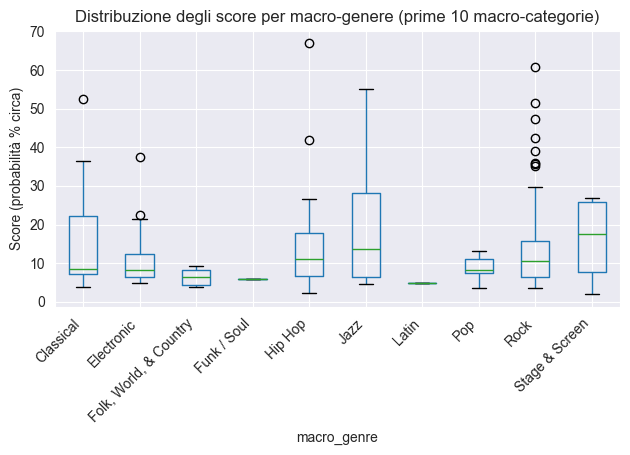

In [67]:
# Boxplot degli score per macro-genere (solo prime N per leggibilità)
top_macro = macro_counts.head(10).index
df_box = df_genres[df_genres["macro_genre"].isin(top_macro)]

plt.figure(figsize=(10, 6))
df_box.boxplot(column="score", by="macro_genre")
plt.xticks(rotation=45, ha="right")
plt.title("Distribuzione degli score per macro-genere (prime 10 macro-categorie)")
plt.suptitle("")  # rimuove il titolo automatico di pandas
plt.ylabel("Score (probabilità % circa)")
plt.tight_layout()
plt.show()


Analisi multivariata: relazioni tra generi

Qui facciamo co-occorrenza dei macro-generi: quali macro-generi compaiono insieme nella stessa traccia tra le top-10?

Questa cella costruisce una tabella di co-occorrenza tra macro-generi. Ogni riga rappresenta una coppia di macro-generi che compaiono insieme almeno in una traccia (nelle top-10 classi). La colonna count indica quante tracce presentano quella combinazione.

In [68]:
from itertools import combinations
from collections import Counter

# Per ogni traccia, prendo l'insieme dei macro-generi presenti (per evitare duplicati)
macro_by_track = (
    df_genres
    .groupby("id")["macro_genre"]
    .apply(lambda s: sorted(set(s)))  # lista di macro-generi unici per traccia
)

# Costruisco un contatore di coppie (g1, g2)
cooc_counter = Counter()

for macros in macro_by_track:
    # genero tutte le coppie (non ordinate) di macro-generi che compaiono insieme
    if len(macros) > 1:
        for g1, g2 in combinations(macros, 2):
            pair = tuple(sorted((g1, g2)))
            cooc_counter[pair] += 1

# Porto tutto in un DataFrame
rows = [{"g1": g1, "g2": g2, "count": cnt} for (g1, g2), cnt in cooc_counter.items()]
df_cooc = pd.DataFrame(rows).sort_values("count", ascending=False)
df_cooc.head(20)


,g1,g2,count
3,Pop,Rock,3
6,Electronic,Rock,3
1,Classical,Stage & Screen,2
0,Classical,Electronic,1
2,Electronic,Stage & Screen,1
4,Electronic,Hip Hop,1
5,Funk / Soul,Rock,1
7,Electronic,Pop,1
8,"Folk, World, & Country",Latin,1
9,"Folk, World, & Country",Non-Music,1


Questa matrice mostra quante volte due macro-generi compaiono insieme come top-classi per la stessa traccia. Valori alti indicano una forte associazione tra generi (es. Rock con Pop Rock, Electronic con House, ecc.).

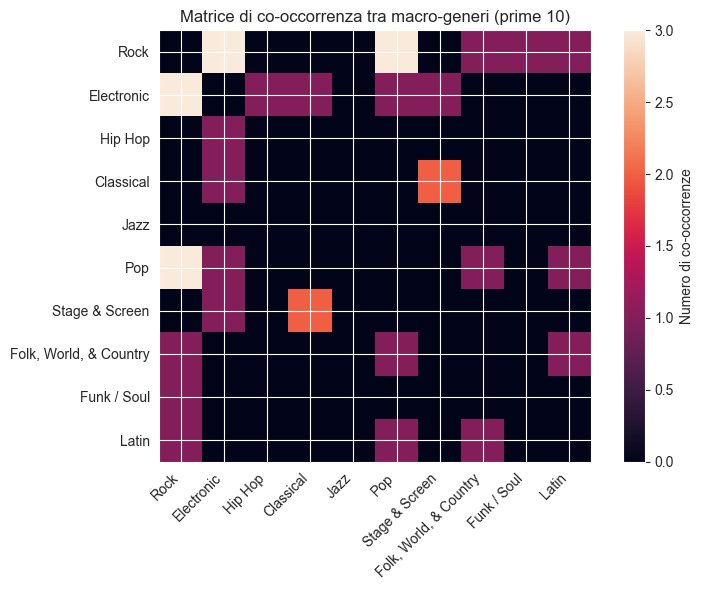

In [69]:
# Seleziono le macro-categorie più frequenti per rendere la matrice leggibile
top_macro = macro_counts.head(10).index

df_cooc_top = df_cooc[
    df_cooc["g1"].isin(top_macro) &
    df_cooc["g2"].isin(top_macro)
].copy()

# Costruisco una matrice simmetrica g1 x g2
cooc_matrix = pd.pivot_table(
    df_cooc_top,
    index="g1",
    columns="g2",
    values="count",
    fill_value=0
)

# Rendo la matrice esplicitamente simmetrica (aggiungo anche la parte inferiore)
cooc_matrix = cooc_matrix.reindex(index=top_macro, columns=top_macro, fill_value=0)

for i in range(len(top_macro)):
    for j in range(i):
        v = max(cooc_matrix.iat[i, j], cooc_matrix.iat[j, i])
        cooc_matrix.iat[i, j] = v
        cooc_matrix.iat[j, i] = v

plt.figure(figsize=(8, 6))
plt.imshow(cooc_matrix.values)
plt.xticks(range(len(top_macro)), top_macro, rotation=45, ha="right")
plt.yticks(range(len(top_macro)), top_macro)
plt.colorbar(label="Numero di co-occorrenze")
plt.title("Matrice di co-occorrenza tra macro-generi (prime 10)")
plt.tight_layout()
plt.show()
